**Questions**
---
How large and sparse is the network? How does cleaning change it?

**Topics Covered**:
* Vertex Degree,
* Degree Sequence and Distribution
* Handshaking theorem,
* Graph Density
* Effects of removing vertices/edges

**Expected Coverage**:
* Node/edge Counts
* Density,
* Degree Statitics and Distribution
* Justify self-loop, low-degree.
* Compare Original vs Processed Graph

## **Libraries and Fixed Variables**

In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

routesFile      = "../data/routes.dat"
routeCols       = ["airline", "airline_id", 
                   "src", "src_id", "dst", "dst_id",
                   "codeshare", "stops", "equipment",]

airlinesFile    = "../data/airlines.dat"
airlineCols     = ["Airline ID", "Name", "Alias", "IATA", "ICAO", 
                   "Callsign", "Country", "Active"]

airportsFile    = "../data/airports.dat"
airportCols     = ['Airport ID', 'Name', 'City', 'Country', 'IATA', 'ICAO', 
                   'Latitude', 'Longitude', 'Altitude', 
                   'Timezone', 'DST', 'Tz database time zone', 'Type', 'Source']


## **Load Data**

In [2]:
routesDataRaw = pd.read_csv(routesFile, header=None, names=routeCols, na_values="\\N", keep_default_na=False)
display(routesDataRaw)

# routesDataRaw["frequency"] = routesDataRaw.groupby(["src", "dst"])["src"].transform("size")
# display(routesDataRaw[routesDataRaw["frequency"] == 1].head())

,airline,airline_id,src,src_id,dst,dst_id,codeshare,stops,equipment
0,2B,410.0,AER,2965.0,KZN,2990.0,,0,CR2
1,2B,410.0,ASF,2966.0,KZN,2990.0,,0,CR2
2,2B,410.0,ASF,2966.0,MRV,2962.0,,0,CR2
3,2B,410.0,CEK,2968.0,KZN,2990.0,,0,CR2
4,2B,410.0,CEK,2968.0,OVB,4078.0,,0,CR2
...,...,...,...,...,...,...,...,...,...
67658,ZL,4178.0,WYA,6334.0,ADL,3341.0,,0,SF3
67659,ZM,19016.0,DME,4029.0,FRU,2912.0,,0,734
67660,ZM,19016.0,FRU,2912.0,DME,4029.0,,0,734
67661,ZM,19016.0,FRU,2912.0,OSS,2913.0,,0,734


## **Data Exploration**

#### **Column Distribution**

In [3]:
totalData = len(routesDataRaw)
for col in routeCols:
    uniqueCount = routesDataRaw[col].unique()
    nanCount = routesDataRaw[routesDataRaw[col].isna() == True]
    print(col)
    print(f"  unique count: {len(uniqueCount)} / {totalData}")
    print(f"  NaN count: {len(nanCount)}")
    # print(f"  Difference: {totalData-len(nanCount)}")
    if len(uniqueCount) <10: print(f"  {list(uniqueCount)}")
    if len(nanCount): display(routesDataRaw.iloc[nanCount.index])

airline
  unique count: 568 / 67663
  NaN count: 0
airline_id
  unique count: 548 / 67663
  NaN count: 479


,airline,airline_id,src,src_id,dst,dst_id,codeshare,stops,equipment
312,3H,NaN,AKV,5506.0,YIK,5504.0,,0,DH8
313,3H,NaN,AKV,5506.0,YPX,6727.0,,0,DH8
314,3H,NaN,XGR,5512.0,YVP,154.0,,0,DHT BET
315,3H,NaN,YGL,62.0,YGW,5496.0,,0,DHT
316,3H,NaN,YGL,62.0,YPX,6727.0,,0,73M
...,...,...,...,...,...,...,...,...,...
66596,ZD,NaN,DZA,915.0,MJN,929.0,,0,AT7
66597,ZD,NaN,DZA,915.0,NOS,930.0,,0,AT7
66598,ZD,NaN,HAH,912.0,DZA,915.0,,0,AT7
66599,ZD,NaN,MJN,929.0,DZA,915.0,,0,AT7


src
  unique count: 3409 / 67663
  NaN count: 0
src_id
  unique count: 3321 / 67663
  NaN count: 220


,airline,airline_id,src,src_id,dst,dst_id,codeshare,stops,equipment
38,2B,410.0,TGK,NaN,DME,4029.0,,0,CR2
54,2G,1654.0,KCK,NaN,IKT,2937.0,,0,AN4
1163,4O,17885.0,PQM,NaN,MEX,1824.0,,0,SU9
2113,5Z,18946.0,PBZ,NaN,CPT,797.0,,0,BEH
2114,5Z,18946.0,PBZ,NaN,JNB,813.0,,0,BEH
...,...,...,...,...,...,...,...,...,...
66353,Z8,603.0,ORU,NaN,SRZ,4247.0,,0,SWM
67468,ZI,21.0,MLH,NaN,ALG,210.0,,0,320
67469,ZI,21.0,MLH,NaN,CZL,221.0,,0,320
67470,ZI,21.0,MLH,NaN,ORN,231.0,,0,319


dst
  unique count: 3418 / 67663
  NaN count: 0
dst_id
  unique count: 3327 / 67663
  NaN count: 221


,airline,airline_id,src,src_id,dst,dst_id,codeshare,stops,equipment
7,2B,410.0,DME,4029.0,TGK,NaN,,0,CR2
48,2G,1654.0,IKT,2937.0,KCK,NaN,,0,AN4
1136,4O,17885.0,MEX,1824.0,PQM,NaN,,0,SU9
2108,5Z,18946.0,CPT,797.0,PBZ,NaN,,0,BEH
2120,6E,2850.0,AMD,2994.0,HYD,NaN,,0,320
...,...,...,...,...,...,...,...,...,...
66361,Z8,603.0,SRZ,4247.0,ORU,NaN,,0,SWM
67443,ZI,21.0,ALG,210.0,MLH,NaN,,0,320
67455,ZI,21.0,CZL,221.0,MLH,NaN,,0,320
67483,ZI,21.0,ORN,231.0,MLH,NaN,,0,319


codeshare
  unique count: 2 / 67663
  NaN count: 0
  ['', 'Y']
stops
  unique count: 2 / 67663
  NaN count: 0
  [np.int64(0), np.int64(1)]
equipment
  unique count: 3946 / 67663
  NaN count: 0


**As mentioned on https://openflights.org/data.php, the following columns are non-vital** 
* `_id`s:  *Unique OpenFlights identifiers* 
* `codeshare`: "Y" if this flight is a codeshare (that is, not operated by Airline, but another carrier), empty otherwise
* `stops`:  Number of stops on this flight ("0" for direct)
* `equipment`: 3-letter codes for plane type(s) generally used on this flight, separated by spaces

so we can safely drop them

#### **Cleaning and Processing of Columns**
We will keep the 3 main identifiers of the flights (`airline`, `src`, `dst`) and add a `frequency` column for the number of unique flights sharing the same route.

In [4]:
routesDataRaw["frequency"] = routesDataRaw.groupby(["src", "dst"])["src"].transform("size")
display(routesDataRaw)
# display(routesDataRaw[routesDataRaw["frequency"] == 1].head())
print("Flights with src == 'FRU' and dst == 'OSS'")
display(routesDataRaw[(routesDataRaw["src"] == "FRU") & (routesDataRaw["dst"] == "OSS")])


,airline,airline_id,src,src_id,dst,dst_id,codeshare,stops,equipment,frequency
0,2B,410.0,AER,2965.0,KZN,2990.0,,0,CR2,1
1,2B,410.0,ASF,2966.0,KZN,2990.0,,0,CR2,1
2,2B,410.0,ASF,2966.0,MRV,2962.0,,0,CR2,1
3,2B,410.0,CEK,2968.0,KZN,2990.0,,0,CR2,1
4,2B,410.0,CEK,2968.0,OVB,4078.0,,0,CR2,2
...,...,...,...,...,...,...,...,...,...,...
67658,ZL,4178.0,WYA,6334.0,ADL,3341.0,,0,SF3,1
67659,ZM,19016.0,DME,4029.0,FRU,2912.0,,0,734,6
67660,ZM,19016.0,FRU,2912.0,DME,4029.0,,0,734,6
67661,ZM,19016.0,FRU,2912.0,OSS,2913.0,,0,734,3


Flights with src == 'FRU' and dst == 'OSS'


,airline,airline_id,src,src_id,dst,dst_id,codeshare,stops,equipment,frequency
47234,QH,882.0,FRU,2912.0,OSS,2913.0,,0,735,3
66138,YK,1943.0,FRU,2912.0,OSS,2913.0,,0,146,3
67661,ZM,19016.0,FRU,2912.0,OSS,2913.0,,0,734,3


In [5]:
routesDataCleaned = routesDataRaw[['src', 'dst', 'airline', 'frequency']].dropna().sort_values(by=["src",'dst',])
display(routesDataCleaned)

,src,dst,airline,frequency
10039,AAE,ALG,AH,1
10040,AAE,CDG,AH,1
10041,AAE,IST,AH,1
10042,AAE,LYS,AH,1
10043,AAE,MRS,AH,2
...,...,...,...,...
30518,ZYI,XMN,GS,1
1056,ZYL,DAC,4H,4
15347,ZYL,DAC,BG,4
48160,ZYL,DAC,RX,4


In [29]:
print("Identifying edges with the same start and end(Self-loops).")
selfLoops = routesDataCleaned[routesDataCleaned["src"] == routesDataCleaned["dst"]]
display(selfLoops)


Identifying edges with the same start and end(Self-loops).


,src,dst,airline,frequency
33276,PKN,PKN,IL,1


In [30]:
print("Removing rows containing self-loops")
routesDataCleaned2 = routesDataCleaned.drop(index=selfLoops.index)
display(routesDataCleaned2)

Removing rows containing self-loops


,src,dst,airline,frequency
10039,AAE,ALG,AH,1
10040,AAE,CDG,AH,1
10041,AAE,IST,AH,1
10042,AAE,LYS,AH,1
10043,AAE,MRS,AH,2
...,...,...,...,...
30518,ZYI,XMN,GS,1
1056,ZYL,DAC,4H,4
15347,ZYL,DAC,BG,4
48160,ZYL,DAC,RX,4


### **Vertice Tabulation from Src & Dst**

In [32]:
srcSet = set(routesDataCleaned2["src"])
dstSet = set(routesDataCleaned2["dst"])

srcOnly = srcSet - dstSet    # airports with departures only
dstOnly = dstSet - srcSet    # airports with arrivals only
both = srcSet & dstSet        # airports in both
total = srcSet | dstSet       # all unique airports

print("Src:".ljust(10), len(srcSet))
print("Dst:".ljust(10), len(dstSet))
print("Src Only:".ljust(10), len(srcOnly), "\n ", srcOnly)
print("Dst Only:".ljust(10), len(dstOnly), "\n ", dstOnly)
print("Both:".ljust(10), len(both))
print("Total:".ljust(10), len(total))

Src:       3409
Dst:       3418
Src Only:  7 
  {'VDA', 'PTJ', 'IUE', 'SXX', 'MSW', 'STZ', 'LJA'}
Dst Only:  16 
  {'BVS', 'CMP', 'FMI', 'CZJ', 'DLZ', 'KYK', 'MTE', 'KZI', 'BSS', 'QFX', 'UII', 'KPR', 'TUA', 'KZB', 'ORX', 'SPI'}
Both:      3402
Total:     3425


In [ ]:
flightList = routesDataCleaned2.drop_duplicates(subset=["src", "dst", "airline",])[["src", "dst", "airline",]]
print("Number of unique flights:", len(flightList))

routeList = routesDataCleaned2.drop_duplicates(subset=["src", "dst",])[["src", "dst", "frequency",]]
print("Number of unique routes:", len(routeList))

flightGraph = nx.from_pandas_edgelist(flightList, "src", "dst", edge_attr="airline", create_using=nx.MultiDiGraph)
print("\nDirected graph with airline attr:")
print(" Number of Nodes(Vertices):", flightGraph.number_of_nodes())
print(" Number of Edges:", flightGraph.number_of_edges())

routeGraph = nx.from_pandas_edgelist(routeList, "src", "dst", edge_attr="frequency", create_using=nx.MultiDiGraph)
print("\nDirected graph with frequency attr:")
print(" Number of Nodes(Vertices):", routeGraph.number_of_nodes())
print(" Number of Edges:", routeGraph.number_of_edges())

undirGraph = routeGraph.to_undirected()   # undirected view for degree theory
print("\nUndirected:")
print(" Number of Nodes(Vertices):", undirGraph.number_of_nodes())
print(" Number of Edges:", undirGraph.number_of_edges())


Number of unique flights: 67662
Number of unique routes: 37594

Directed graph with airline attr:
 Number of Nodes(Vertices): 3425
 Number of Edges: 67662

Directed graph with frequency attr:
 Number of Nodes(Vertices): 3425
 Number of Edges: 37594

Undirected:
 Number of Nodes(Vertices): 3425
 Number of Edges: 19256


In [79]:
minDegree = 3
degreeRange = range(1,5)

In [80]:
bottom4Degrees = dict()
for degree in degreeRange:
    xDegreeNodes = [v for v, d in flightGraph.degree() if d == degree]
    bottom4Degrees[degree] = xDegreeNodes

for key, value in bottom4Degrees.items():
    print(f"Degree: {key}", f"No of Nodes: {len(value)} ", f"Ratio of total Nodes: {len(value)/flightGraph.number_of_nodes():.4f}", sep='\t')


lowDegreeNodes = [v for v, d in flightGraph.degree() if d < minDegree]
processedGraph = flightGraph.copy()
processedGraph.remove_nodes_from(lowDegreeNodes)

# print("Self-loops removed:", originalGraph.number_of_edges() - processedGraph.number_of_edges())
print(f"Low-degree (less than {minDegree}) vertices removed: {len(lowDegreeNodes)} of {flightGraph.number_of_nodes()}")

Degree: 1	No of Nodes: 21 	Ratio of total Nodes: 0.0061
Degree: 2	No of Nodes: 681 	Ratio of total Nodes: 0.1988
Degree: 3	No of Nodes: 44 	Ratio of total Nodes: 0.0128
Degree: 4	No of Nodes: 539 	Ratio of total Nodes: 0.1574
Low-degree (less than 3) vertices removed: 702 of 3425


In [81]:
bottom4Degrees = dict()
for degree in degreeRange:
    xDegreeNodes = [v for v, d in routeGraph.degree() if d == degree]
    bottom4Degrees[degree] = xDegreeNodes

for key, value in bottom4Degrees.items():
    print(f"Degree: {key}", f"No of Nodes: {len(value)}  ", f"Ratio of total Nodes: {len(value)/routeGraph.number_of_nodes():.4f}", sep='\t')

lowDegreeNodes = [v for v, d in routeGraph.degree() if d < minDegree]
processedGraph = routeGraph.copy()
processedGraph.remove_nodes_from(lowDegreeNodes)

# print("Self-loops removed:", originalGraph.number_of_edges() - processedGraph.number_of_edges())
print(f"Low-degree (less than {minDegree}) vertices removed: {len(lowDegreeNodes)} of {routeGraph.number_of_nodes()}")

Degree: 1	No of Nodes: 21  	Ratio of total Nodes: 0.0061
Degree: 2	No of Nodes: 867  	Ratio of total Nodes: 0.2531
Degree: 3	No of Nodes: 64  	Ratio of total Nodes: 0.0187
Degree: 4	No of Nodes: 610  	Ratio of total Nodes: 0.1781
Low-degree (less than 3) vertices removed: 888 of 3425


In [82]:
bottom4Degrees = dict()
for degree in degreeRange:
    xDegreeNodes = [v for v, d in undirGraph.degree() if d == degree]
    bottom4Degrees[degree] = xDegreeNodes

for key, value in bottom4Degrees.items():
    print(f"Degree: {key}", f"No of Nodes: {len(value)}  ", f"Ratio of total Nodes: {len(value)/undirGraph.number_of_nodes():.4f}", sep='\t')

lowDegreeNodes = [v for v, d in undirGraph.degree() if d < minDegree]
processedGraph = undirGraph.copy()
processedGraph.remove_nodes_from(lowDegreeNodes)

# print("Self-loops removed:", originalGraph.number_of_edges() - processedGraph.number_of_edges())
print(f"Low-degree (less than {minDegree}) vertices removed: {len(lowDegreeNodes)} of {undirGraph.number_of_nodes()}")

Degree: 1	No of Nodes: 768  	Ratio of total Nodes: 0.2242
Degree: 2	No of Nodes: 744  	Ratio of total Nodes: 0.2172
Degree: 3	No of Nodes: 407  	Ratio of total Nodes: 0.1188
Degree: 4	No of Nodes: 237  	Ratio of total Nodes: 0.0692
Low-degree (less than 3) vertices removed: 1512 of 3425


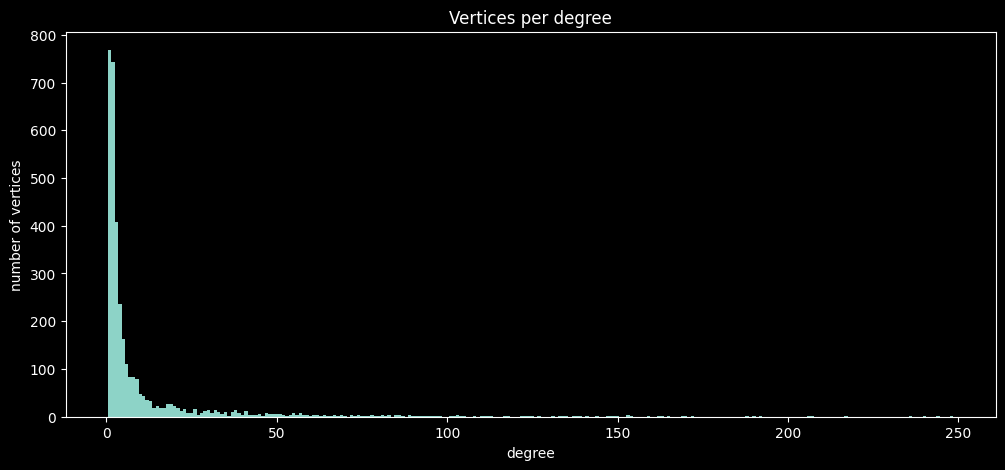

In [83]:
def vertexCountByDegree(G):
    return pd.Series([d for _, d in G.degree()]).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 5))

degCounts = vertexCountByDegree(undirGraph)
ax.bar(degCounts.index, degCounts.values, width=1.0)
ax.set(title="Vertices per degree", xlabel="degree", ylabel="number of vertices")

plt.show()

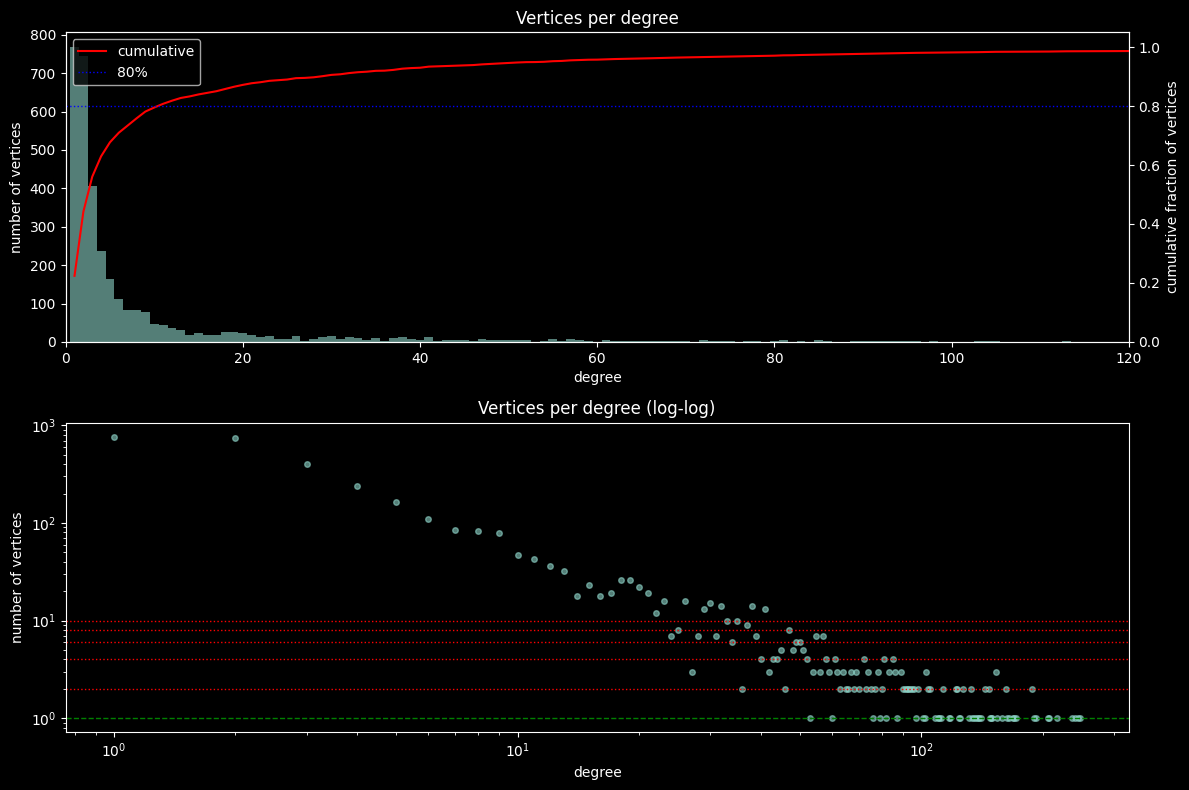

In [84]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

degCounts = vertexCountByDegree(undirGraph)
axes[0].bar(degCounts.index, degCounts.values, alpha=0.6, label="original", width=1.0)
axes[0].set(title="Vertices per degree", xlabel="degree", ylabel="number of vertices")
axes[0].set_xlim(0,120)

ax2 = axes[0].twinx()
cum = degCounts.sort_index().cumsum()
ax2.plot(cum.index, cum.values / cum.values[-1], color="red", lw=1.5, label="cumulative")
ax2.axhline(0.8, color="blue",ls=":", lw=1, label="80%")
ax2.set_ylabel("cumulative fraction of vertices")
ax2.set_ylim(0, 1.05)
ax2.legend()

axes[1].loglog(degCounts.index, degCounts.values, "o", ms=4, alpha=0.6, label="original")
axes[1].set(title="Vertices per degree (log-log)", xlabel="degree", ylabel="number of vertices")
for i in range(2,11,2):
    axes[1].axhline(i, color="red", ls=":", lw=1,)
axes[1].axhline(1, color="green", ls="--", lw=1, label="1 vertice")

# for ax in axes:
#     ax.legend()
plt.tight_layout()
plt.show()

### **Exploration of Edges**

In [85]:
routesDataRaw["frequency"] = routesDataRaw.groupby(["src", "dst"])["src"].transform("size")
uniqueEdges = (
    routesDataRaw.drop(columns=['codeshare','stops', 'frequency'])
    .groupby(by=["src", "dst"])
    .nunique()
)
uniqueEdges["frequency"] = routesDataRaw.groupby(["src", "dst"]).size()

print("no of Edges:", len(uniqueEdges))
display(uniqueEdges)

display(uniqueEdges.loc[('AAE',)])

no of Edges: 37595


airline  airline_id  src_id  dst_id  equipment  frequency
src dst                                                           
AAE ALG        1           1       1       1          1          1
    CDG        1           1       1       1          1          1
    IST        1           1       1       1          1          1
    LYS        1           1       1       1          1          1
    MRS        2           2       1       1          2          2
...          ...         ...     ...     ...        ...        ...
ZYI SZX        1           1       1       1          1          1
    WUH        1           1       1       1          1          1
    XIY        1           1       1       1          1          1
    XMN        1           1       1       1          1          1
ZYL DAC        4           4       1       1          4          4

[37595 rows x 6 columns]

,airline,airline_id,src_id,dst_id,equipment,frequency
dst,,,,,,
ALG,1,1,1,1,1,1
CDG,1,1,1,1,1,1
IST,1,1,1,1,1,1
LYS,1,1,1,1,1,1
MRS,2,2,1,1,2,2
ORN,1,1,1,1,1,1
ORY,2,2,1,1,2,2


In [86]:
duplicateCount = routesDataRaw[["src", "dst"]].duplicated().sum()
display(duplicateCount)
counts = routesDataRaw[["src", "dst"]].dropna().value_counts()
display(pd.DataFrame(counts))

np.int64(30068)

,,count
src,dst,
ORD,ATL,20
ATL,ORD,19
HKT,BKK,13
ORD,MSY,13
ATL,MIA,12
...,...,...
TSV,WIN,1
WGA,MEL,1
WIN,LRE,1


In [87]:
query = routesDataRaw[routesDataRaw["src"] == "TSV"]
display(query)

,airline,airline_id,src,src_id,dst,dst_id,codeshare,stops,equipment,frequency
6912,AA,24.0,TSV,3330.0,BNE,3320.0,Y,0,737,4
35058,JQ,3052.0,TSV,3330.0,BNE,3320.0,,0,320,4
35059,JQ,3052.0,TSV,3330.0,MEL,3339.0,,0,321,1
35060,JQ,3052.0,TSV,3330.0,SYD,3361.0,,0,320,2
47148,QF,4089.0,TSV,3330.0,BNE,3320.0,,0,73H,4
47149,QF,4089.0,TSV,3330.0,CNJ,6255.0,Y,0,DH4,1
47150,QF,4089.0,TSV,3330.0,CNS,3322.0,Y,0,DH3 DH4,1
47151,QF,4089.0,TSV,3330.0,DRW,3999.0,Y,0,E70,2
47152,QF,4089.0,TSV,3330.0,ISA,3324.0,Y,0,DH4,2
47153,QF,4089.0,TSV,3330.0,MKY,3326.0,Y,0,DH4 DH3,1
